In [5]:
# Setup and Imports
import os
import torch
import torch.nn as nn
from torchvision import datasets, models, transforms
from torch.utils.data import DataLoader
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import glob
from PIL import Image

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

# Custom ImageFolder that doesn't crash on empty folders
class CustomImageFolder(torch.utils.data.Dataset):
    def __init__(self, root, transform=None):
        self.root = root
        self.transform = transform
        self.classes = sorted([d.name for d in os.scandir(root) if d.is_dir()])
        self.class_to_idx = {cls_name: i for i, cls_name in enumerate(self.classes)}
        self.samples = []
        for cls_name in self.classes:
            cls_dir = os.path.join(root, cls_name)
            for ext in ('*.png', '*.jpg', '*.jpeg', '*.bmp', '*.tif', '*.tiff', '*.PNG', '*.JPG', '*.JPEG', '*.BMP', '*.TIF', '*.TIFF'):
                for path in glob.glob(os.path.join(cls_dir, ext)):
                    self.samples.append((path, self.class_to_idx[cls_name]))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        path, target = self.samples[index]
        sample = Image.open(path).convert('RGB')
        if self.transform is not None:
            sample = self.transform(sample)
        return sample, target


Device: cuda


In [6]:
# Model Definition (ResNet50)
class Modelku(nn.Module):
    def __init__(self, num_classes: int):
        super().__init__()
        self.model = models.resnet50(weights=None)
        in_features = self.model.fc.in_features
        self.model.fc = nn.Sequential(
            nn.Dropout(p=0.4, inplace=True),
            nn.Linear(in_features, num_classes)
        )

    def forward(self, x: torch.Tensor):
        return self.model(x)


In [7]:
# Configuration and Transforms
data_root = 'generalisasi'

# Transform 1: 224x224 + ImageNet Normalization (BCCD, LISC)
transform_224 = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Transform 2: 64x64 + No Normalization (WBC, MK)
transform_64 = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor()
])

datasets_to_test = ['BCCD', 'BCCD_transfered', 'LISC', 'LISC_transfered', 'wbc', 'mk']


Using 224x224 and ImageNet normalization for BCCD

Evaluating BCCD with checkpoint/generalisasi/bestBccd.pt...
[BCCD] Acc: 0.8406, Prec: 0.8128, Rec: 0.7057, F1: 0.7381


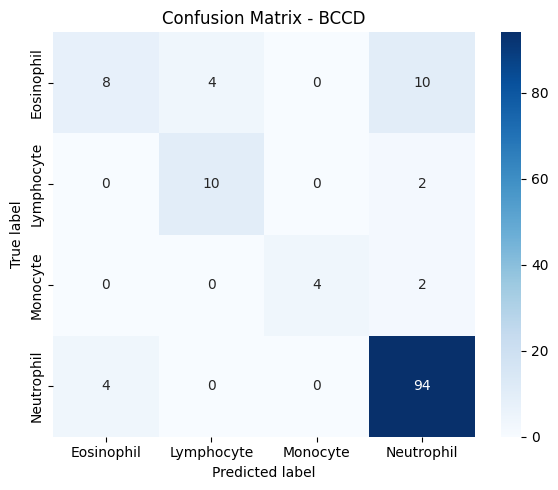

Using 224x224 and ImageNet normalization for BCCD_transfered

Evaluating BCCD_transfered with checkpoint/generalisasi/bestBccd_transfered.pt...
[BCCD_transfered] Acc: 0.8551, Prec: 0.8600, Rec: 0.7650, F1: 0.8027


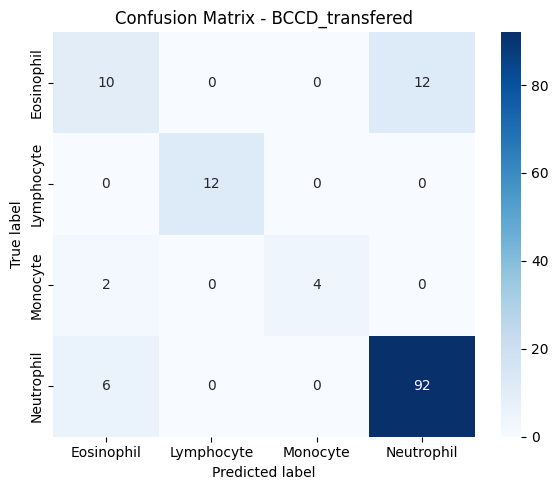

Using 224x224 and ImageNet normalization for LISC

Evaluating LISC with checkpoint/generalisasi/bestLisc.pt...
[LISC] Acc: 0.9870, Prec: 0.9875, Rec: 0.9875, F1: 0.9871


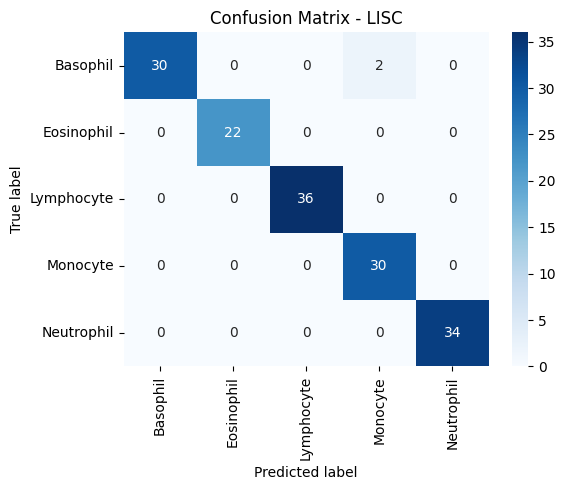

Using 224x224 and ImageNet normalization for LISC_transfered

Evaluating LISC_transfered with checkpoint/generalisasi/bestLisc_transfered.pt...
[LISC_transfered] Acc: 1.0000, Prec: 1.0000, Rec: 1.0000, F1: 1.0000


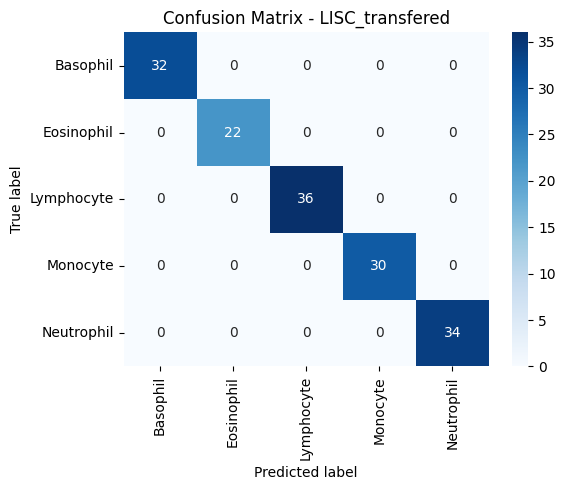

Using 64x64 and NO normalization for wbc

Evaluating wbc with checkpoint/generalisasi/bestWbc.pt...
[wbc] Acc: 0.9173, Prec: 0.9229, Rec: 0.9173, F1: 0.9180


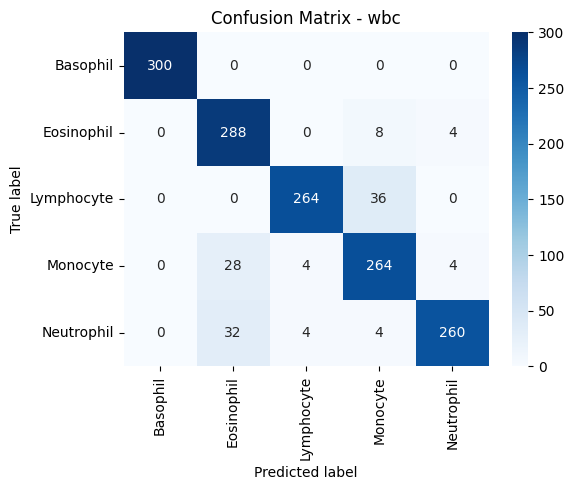

Using 64x64 and NO normalization for mk

Evaluating mk with checkpoint/generalisasi/bestMk.pt...
[mk] Acc: 0.9453, Prec: 0.9470, Rec: 0.9453, F1: 0.9456


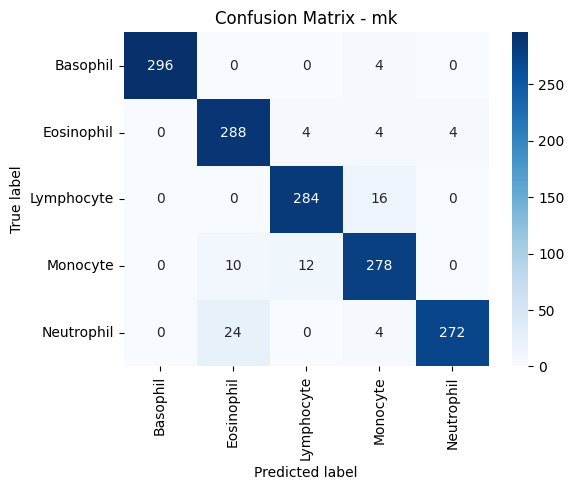


Summary of Results:
Dataset              | Acc      | Prec     | Rec      | F1      
-----------------------------------------------------------------
BCCD                 | 0.8406   | 0.8128   | 0.7057   | 0.7381
BCCD_transfered      | 0.8551   | 0.8600   | 0.7650   | 0.8027
LISC                 | 0.9870   | 0.9875   | 0.9875   | 0.9871
LISC_transfered      | 1.0000   | 1.0000   | 1.0000   | 1.0000
wbc                  | 0.9173   | 0.9229   | 0.9173   | 0.9180
mk                   | 0.9453   | 0.9470   | 0.9453   | 0.9456


In [8]:
# Evaluation Loop
results = {}

for ds_name in datasets_to_test:
    train_ds_path = os.path.join(data_root, ds_name, 'Train')
    val_ds_path = os.path.join(data_root, ds_name, 'Val')
    ckpt_path = f"checkpoint/generalisasi/best{ds_name.capitalize()}.pt"
    
    if not os.path.exists(val_ds_path) or not os.path.exists(train_ds_path):
        print(f"Dataset {ds_name} Train/Val folders not found. Skipping.")
        continue
        
    if not os.path.exists(ckpt_path):
        print(f"Checkpoint {ckpt_path} not found. Skipping.")
        continue

    # Select the correct transform
    if ds_name.lower() in ['wbc', 'mk']:
        current_transform = transform_64
        print(f"Using 64x64 and NO normalization for {ds_name}")
    else:
        current_transform = transform_224
        print(f"Using 224x224 and ImageNet normalization for {ds_name}")

    # 1. Load Training Dataset to get classes (to define model FC layer size)
    train_dataset = CustomImageFolder(root=train_ds_path)
    train_classes = train_dataset.classes
    
    # 2. Load Validation Dataset
    val_dataset = CustomImageFolder(root=val_ds_path, transform=current_transform)
    
    if len(val_dataset) == 0:
        print(f"Validation dataset {ds_name} empty. Skipping.")
        continue
        
    loader = DataLoader(val_dataset, batch_size=64, shuffle=False, num_workers=0)
    
    # 3. Load Model
    model = Modelku(num_classes=len(train_classes)).to(device)
    state_dict = torch.load(ckpt_path, map_location=device, weights_only=False)
    missing, unexpected = model.load_state_dict(state_dict, strict=False)
    model.eval()
    
    y_true = []
    y_pred = []
    
    print(f"\n" + "="*50)
    print(f"Evaluating {ds_name} with {ckpt_path}...")
    print("="*50)
    
    with torch.inference_mode():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)
            preds = logits.argmax(dim=1)
            y_true.extend(yb.cpu().numpy())
            y_pred.extend(preds.cpu().numpy())
            
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, average='macro', zero_division=0)
    rec = recall_score(y_true, y_pred, average='macro', zero_division=0)
    f1 = f1_score(y_true, y_pred, average='macro', zero_division=0)
    
    results[ds_name] = {'Accuracy': acc, 'Precision': prec, 'Recall': rec, 'F1': f1}
    print(f"[{ds_name}] Acc: {acc:.4f}, Prec: {prec:.4f}, Rec: {rec:.4f}, F1: {f1:.4f}")
    
    # Confusion Matrix
    present_labels_idx = np.unique(np.concatenate((y_true, y_pred)))
    present_classes = [train_classes[i] for i in present_labels_idx]
    
    cm = confusion_matrix(y_true, y_pred, labels=present_labels_idx)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=present_classes, yticklabels=present_classes)
    plt.title(f'Confusion Matrix - {ds_name}')
    plt.ylabel('True label')
    plt.xlabel('Predicted label')
    plt.tight_layout()
    plt.show()

print("\nSummary of Results:")
print(f"{'Dataset':<20} | {'Acc':<8} | {'Prec':<8} | {'Rec':<8} | {'F1':<8}")
print("-" * 65)
for ds, metrics in results.items():
    print(f"{ds:<20} | {metrics['Accuracy']:.4f}   | {metrics['Precision']:.4f}   | {metrics['Recall']:.4f}   | {metrics['F1']:.4f}")
